In [9]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import GofChisquarePower

In [10]:
"""
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)

dic_of_mafs = {}
snp_num = 0
true_mean = 0
true_effect = 5
iteration = 200
min_power = 0.9
for file_name in os.listdir('./data/genotype'):
    

    geno = pd.read_pickle(f"./data/genotype/{file_name}")
    geno[geno.columns[snp_num]].value_counts()
    num_maj = geno[geno.columns[snp_num]].value_counts()[1]
    num_het = geno[geno.columns[snp_num]].value_counts()[0]
    try:
        num_min = geno[geno.columns[snp_num]].value_counts()[-1]
    except Exception as e:
        num_min = 0
    total_humans = num_maj + num_het + num_min
    maf = (num_min*2 + num_het)/(total_humans*2)
    dic_of_mafs[maf] = {}
    for ratio in list(range(40))[1:]:
        ratio = ratio/2
        true_sd = true_effect*ratio


        """
        Loop for nul hypothesis
        """
        estimated_effect_nul = []
        estimated_intercept_nul = []
        SE_nul = []
        p_nul = []
        
        i = 0
        for i in range(iteration):
            mean_min = true_mean
            mean_het = true_mean
            mean_maj = true_mean
            sigma_min = true_sd
            sigma_het = true_sd
            sigma_maj = true_sd
            pheno = []
            for var in list(geno[geno.columns[snp_num]]):
                if var == 1:
                    pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
                elif var == 0:
                    pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
                else:
                    pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
            df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno_null": pheno})

            X = df_pheno[['geno']]
            y = df_pheno[['pheno_null']]
            reg = LinearRegression().fit(X, y)
            estimated_effect_nul.append(reg.coef_[0][0])
            estimated_intercept_nul.append(reg.intercept_[0])

            # Calculating p values and standard error
            N = len(X)
            p = len(X.columns) + 1
            X_with_intercept = np.empty(shape=(N, p), dtype=float)
            X_with_intercept[:, 0] = 1
            X_with_intercept[:, 1:p] = X.values

            params = np.append(reg.intercept_,reg.coef_)
            predictions = reg.predict(X)
            new_y = (y-predictions)**2
            newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
            MSE = (sum(list(new_y['pheno_null'])))/(len(newX)-len(newX.columns))

            var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())


            sd_b = np.sqrt(var_b)
            ts_b = params/ sd_b

            p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]

            SE_nul.append(sd_b[1])
            p_nul.append(p_values[1])
        
        """
        Iterate for alternate hypothesis
        """
        estimated_effect_alt = []
        estimated_intercept_alt = []
        SE_alt = []
        p_alt = []

        for i in range(iteration):
            mean_min = true_mean - true_effect
            mean_het = true_mean
            mean_maj = true_mean + true_effect
            sigma_min = true_sd
            sigma_het = true_sd
            sigma_maj = true_sd
            pheno = []
            for var in list(geno[geno.columns[snp_num]]):
                if var == 1:
                    pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
                elif var == 0:
                    pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
                else:
                    pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
            df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno": pheno})

            X = df_pheno[['geno']]
            y = df_pheno[['pheno']]
            reg = LinearRegression().fit(X, y)
            estimated_effect_alt.append(reg.coef_[0][0])
            estimated_intercept_alt.append(reg.intercept_[0])

            # Calculating p values and standard error
            N = len(X)
            p = len(X.columns) + 1
            X_with_intercept = np.empty(shape=(N, p), dtype=float)
            X_with_intercept[:, 0] = 1
            X_with_intercept[:, 1:p] = X.values

            params = np.append(reg.intercept_,reg.coef_)
            predictions = reg.predict(X)
            new_y = (y-predictions)**2
            newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
            MSE = (sum(list(new_y['pheno'])))/(len(newX)-len(newX.columns))

            var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
            sd_b = np.sqrt(var_b)
            ts_b = params/ sd_b

            p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]
            SE_alt.append(sd_b[1])
            p_alt.append(p_values[1])
            
        
        dis_only_alt = pd.DataFrame(data={"Z": list(estimated_effect_alt)})
        dis_only_alt['Z2'] = (dis_only_alt['Z']/SE_alt)**2
        cuttof = stats.chi2.ppf(min_power, df=1)
        omega = 0
        for val in list(dis_only_alt['Z2']):
            if val > cuttof:
                omega += 1
            else:
                pass
        power = round(omega/len(list(dis_only_alt['Z2']))*100,8)
        dic_of_mafs[maf][ratio] = power
pd.DataFrame(data = dic_of_mafs).to_pickle("./df_ratio_vs_power.pkl")
"""

In [17]:
df_ratios_power = pd.read_pickle("./df_ratio_vs_power.pkl")

In [23]:
df_ratios_power[[df_ratios_power.columns[0]]]

Float64Index([ 0.5,  1.0,  1.5,  2.0,  2.5,  3.0,  3.5,  4.0,  4.5,  5.0,  5.5,
               6.0,  6.5,  7.0,  7.5,  8.0,  8.5,  9.0,  9.5, 10.0, 10.5, 11.0,
              11.5, 12.0, 12.5, 13.0, 13.5, 14.0, 14.5, 15.0, 15.5, 16.0, 16.5,
              17.0, 17.5, 18.0, 18.5, 19.0, 19.5],
             dtype='float64')

In [25]:
sns_plot = sns.displot(df_ratios_power[[df_ratios_power.columns[1]]], x=df_ratios_power.columns[1],kind="kde",fill=True)

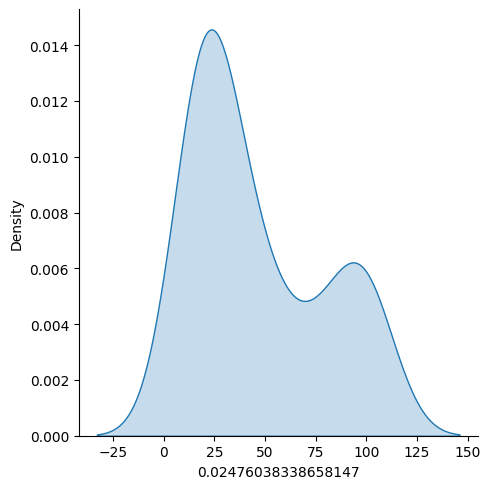

In [26]:
plt.show()